In [2]:
import os
import glob
import pandas as pd
import numpy as np

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

In [3]:
patron_archivos = "datasets/*.csv"
lista_archivos = sorted(glob.glob(patron_archivos))

df_lista = [pd.read_csv(archivo) for archivo in lista_archivos]
df_unificado = pd.concat(df_lista, ignore_index=True)

X = df_unificado.iloc[:, :10].values
y = df_unificado["NOX"].values

X_unificado = df_unificado.iloc[:, :10].values

m = df_unificado.shape[0]
print(f"Total de filas y columnas del conjunto unificado: {m}")

print(("{:>12s}" * 11).format(
    'X[:,0]', 'X[:,1]', 'X[:,2]', 'X[:,3]', 'X[:,4]', 'X[:,5]', 'X[:,6]', 'X[:,7]', 'X[:,8]', 'X[:,9]', 'y (NOX)'
))
print('-' * 132)

for i in range(10):
    print(("{:12.2f}" * 11).format(X[i, 0], X[i, 1], X[i, 2], X[i, 3], X[i, 4],X[i, 5], X[i, 6], X[i, 7], X[i, 8], X[i, 9], y[i]))

Total de filas y columnas del conjunto unificado: 36733
      X[:,0]      X[:,1]      X[:,2]      X[:,3]      X[:,4]      X[:,5]      X[:,6]      X[:,7]      X[:,8]      X[:,9]     y (NOX)
------------------------------------------------------------------------------------------------------------------------------------
        4.59     1018.70       83.67        3.58       23.98     1086.20      549.83      134.67       11.90        0.33       81.95
        4.29     1018.30       84.23        3.57       23.95     1086.10      550.05      134.67       11.89        0.45       82.38
        3.90     1018.40       84.86        3.58       23.99     1086.50      550.19      135.10       12.04        0.45       83.78
        3.74     1018.30       85.43        3.58       23.91     1086.50      550.17      135.03       11.99        0.23       82.50
        3.75     1017.80       85.18        3.58       23.92     1085.90      550.00      134.67       11.91        0.27       82.03
        3.89 

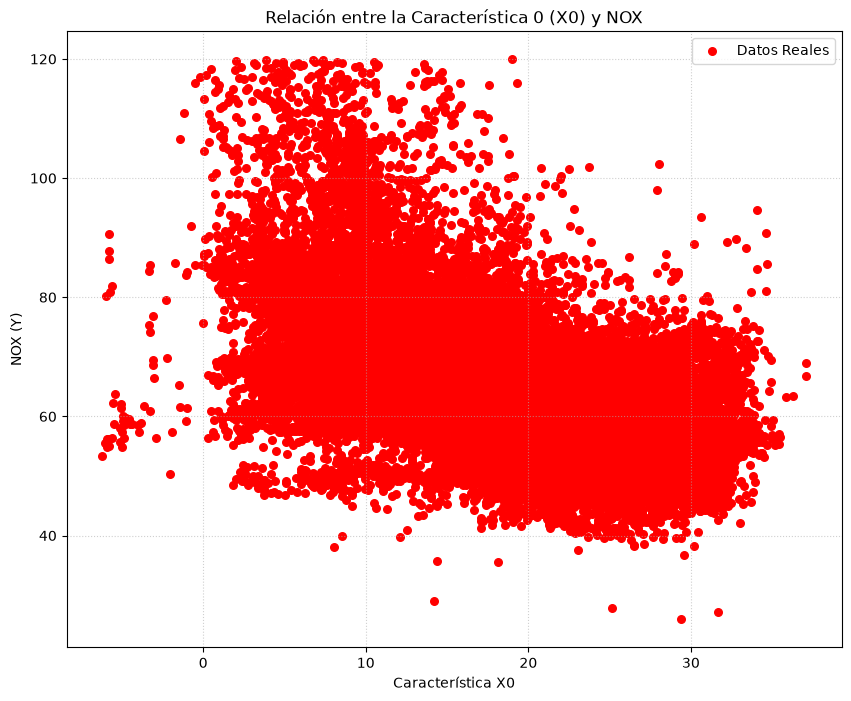

In [4]:
pyplot.figure(figsize=(10, 8))
pyplot.scatter(X[:, 0], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 0 (X0) y NOX', fontsize=12)
pyplot.xlabel('Característica X0', fontsize=10)
pyplot.ylabel('NOX (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

pyplot.show()

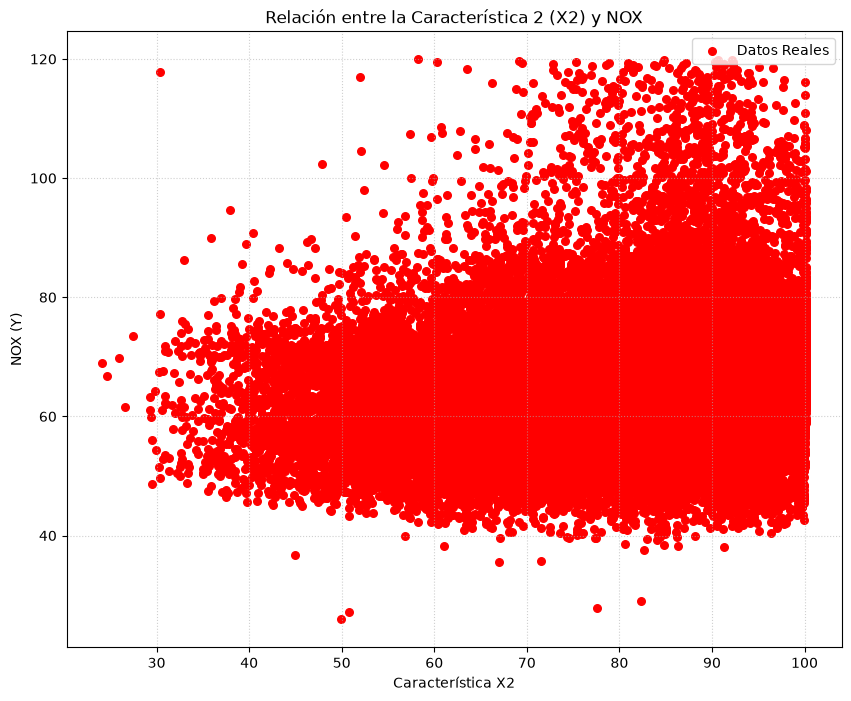

In [5]:
pyplot.figure(figsize=(10, 8))
pyplot.scatter(X[:, 2], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 2 (X2) y NOX', fontsize=12)
pyplot.xlabel('Característica X2', fontsize=10)
pyplot.ylabel('NOX (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

pyplot.show()

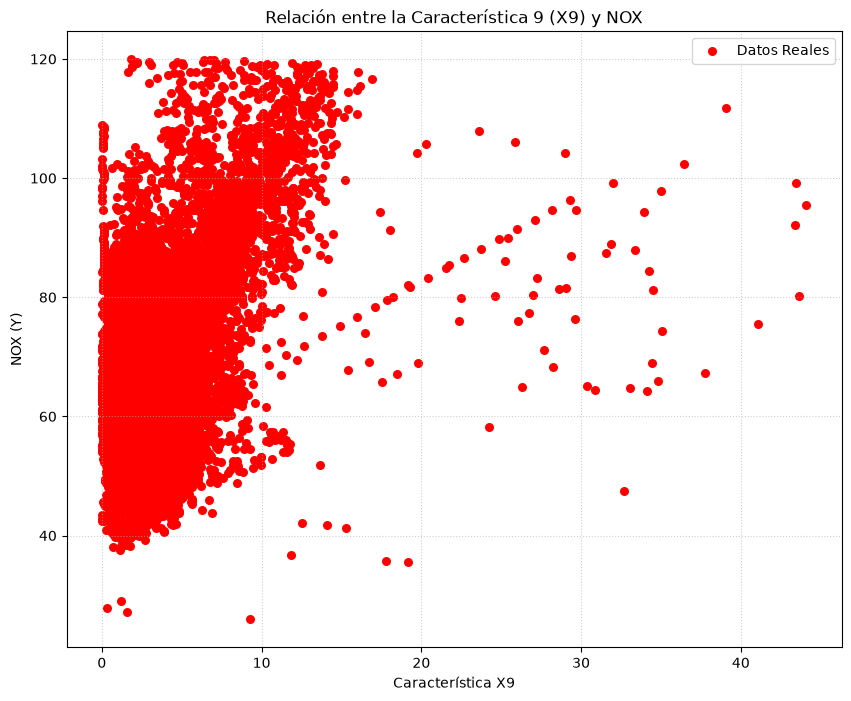

In [6]:
pyplot.figure(figsize=(10, 8))
pyplot.scatter(X[:, 9], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 9 (X9) y NOX', fontsize=12)
pyplot.xlabel('Característica X9', fontsize=10)
pyplot.ylabel('NOX (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

pyplot.show()

In [7]:
X = np.concatenate([X, X * X], axis=1)

print(X)

[[4.58780000e+00 1.01870000e+03 8.36750000e+01 ... 1.81360089e+04
  1.41562404e+02 1.06687157e-01]
 [4.29320000e+00 1.01830000e+03 8.42350000e+01 ... 1.81360089e+04
  1.41419664e+02 2.00560666e-01]
 [3.90450000e+00 1.01840000e+03 8.48580000e+01 ... 1.82520100e+04
  1.45009764e+02 2.03798074e-01]
 ...
 [5.48200000e+00 1.02850000e+03 9.52190000e+01 ... 1.16229961e+04
  1.09453444e+02 1.30279396e+02]
 [5.88370000e+00 1.02870000e+03 9.42000000e+01 ... 1.72685881e+04
  1.38556441e+02 1.09786196e+01]
 [6.03920000e+00 1.02880000e+03 9.45470000e+01 ... 1.57276681e+04
  1.31377444e+02 1.43544361e+02]]


In [8]:
def  featureNormalize(X):
    X_norm = X.copy()
    mu = np.zeros(X.shape[1])
    sigma = np.zeros(X.shape[1])

    mu = np.mean(X, axis = 0)
    sigma = np.std(X, axis = 0)
    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma

X_norm, mu, sigma = featureNormalize(X)

print(X_norm)

[[-1.76236198  0.87105219  0.40162651 ...  0.01618192 -0.19110987
  -0.23880261]
 [-1.80191968  0.8091639   0.44035094 ...  0.01618192 -0.19648049
  -0.23669602]
 [-1.85411274  0.82463597  0.48343186 ...  0.04374043 -0.06140228
  -0.23662337]
 ...
 [-1.64229242  2.38731536  1.19990283 ... -1.5311215  -1.39921576
   2.68237333]
 [-1.58835377  2.4182595   1.12943821 ... -0.18989217 -0.30420982
   0.00517193]
 [-1.56747386  2.43373158  1.15343352 ... -0.55597018 -0.57432098
   2.98004937]]


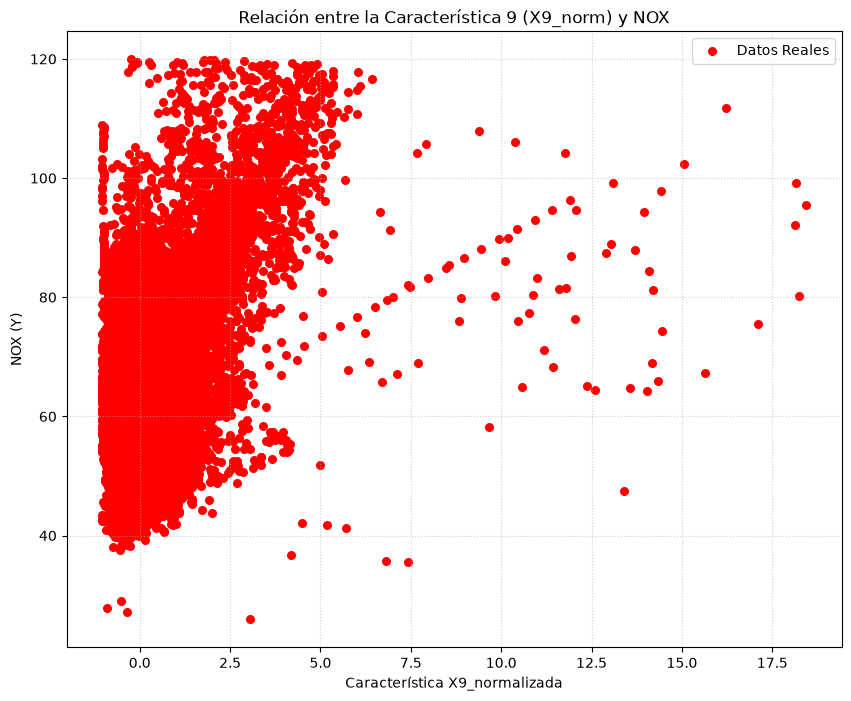

In [9]:
pyplot.figure(figsize=(10, 8))
pyplot.scatter(X_norm[:, 9], y, color='red', s=30, label='Datos Reales')

pyplot.title('Relación entre la Característica 9 (X9_norm) y NOX', fontsize=12)
pyplot.xlabel('Característica X9_normalizada', fontsize=10)
pyplot.ylabel('NOX (Y)', fontsize=10)
pyplot.grid(True, linestyle=':', alpha=0.6)
pyplot.legend(loc='upper right')

In [10]:
X = np.concatenate([np.ones((m, 1)), X_norm], axis=1)

print(f"Dimensiones de X antes: {X_norm.shape}")
print(f"Dimensiones de X ahora (con x0): {X.shape}")

print("\nPrimeras 3 filas y primeras 4 columnas de X:")
print(X[:3, :4])


Dimensiones de X antes: (36733, 20)
Dimensiones de X ahora (con x0): (36733, 21)

Primeras 3 filas y primeras 4 columnas de X:
[[ 1.         -1.76236198  0.87105219  0.40162651]
 [ 1.         -1.80191968  0.8091639   0.44035094]
 [ 1.         -1.85411274  0.82463597  0.48343186]]


In [11]:
def computeCostMulti(X, y, theta):

    m = y.shape[0]

    J = 0

    h = np.dot(X, theta)

    J = (1/(2 * m)) * np.sum(np.square(np.dot(X, theta) - y))

    return J

In [12]:
def gradientDescentMulti(X, y, theta, alpha, num_iters):

    m = y.shape[0]

    theta = theta.copy()

    J_history = []

    for i in range(num_iters):
        theta = theta - (alpha / m) * (np.dot(X, theta) - y).dot(X)
        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history

Theta calculado por el descenso por el gradiente: [ 65.29306727 -12.07197913  -0.65261394  -4.64097344  -1.69301649
   1.04147887  11.67493004  -4.96865674  -4.8145675   -3.55704265
   5.98403691   1.36981113  -0.64956799   1.90581789   2.43317333
  -3.87210619  13.3088915   -5.89937427 -11.55422205  -7.84585195
  -1.8747765 ]


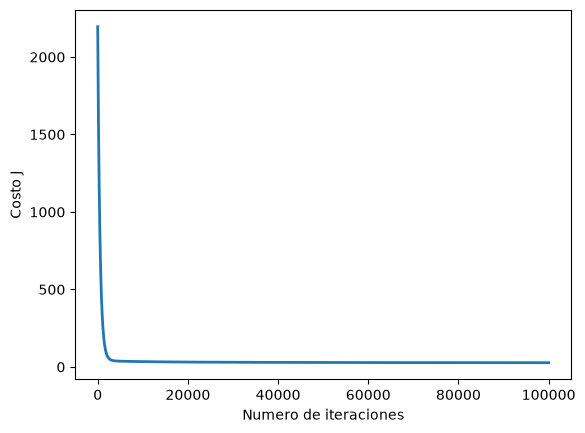

In [13]:
alpha = 0.001
num_iters = 100000

theta = np.zeros(X.shape[1])
theta, J_history = gradientDescentMulti(X, y, theta, alpha, num_iters)

pyplot.plot(np.arange(len(J_history)), J_history, lw=2)
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')

print('Theta calculado por el descenso por el gradiente: {:s}'.format(str(theta)))

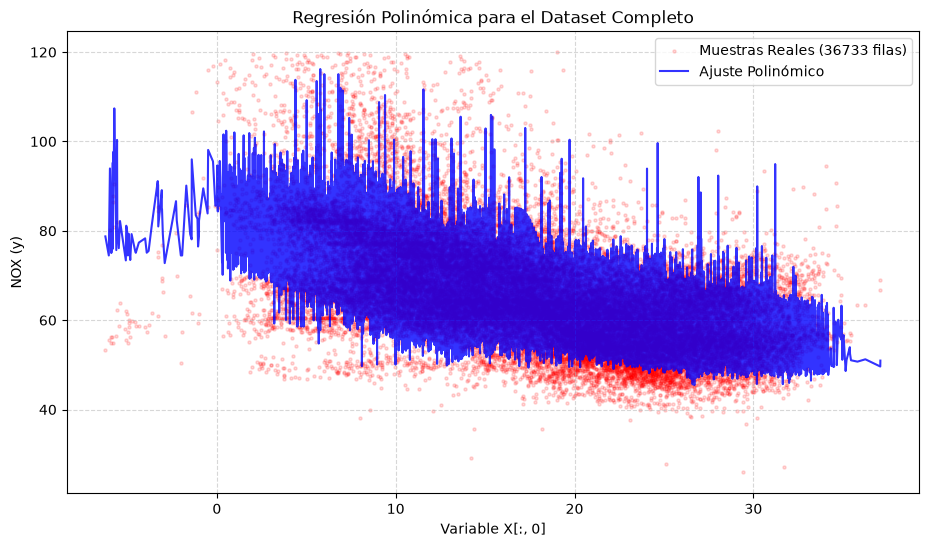

In [16]:
y_pred = np.dot(X, theta).flatten()
y_real = y.flatten()

x0 = df_unificado.iloc[:, 0].values

indices = np.argsort(x0)
x0_ordenado = x0[indices]
y_pred_ordenado = y_pred[indices]

pyplot.figure(figsize=(11, 6))
pyplot.scatter(x0,y_real,color="red",alpha=0.15,s=5,label=f"Muestras Reales ({len(y_real)} filas)",)
pyplot.plot(x0_ordenado,y_pred_ordenado,color="blue",linewidth=1.5,alpha=0.8,label="Ajuste Polinómico",)
pyplot.xlabel("Variable X[:, 0]")
pyplot.ylabel("NOX (y)")
pyplot.title("Regresión Polinómica para el Dataset Completo")
pyplot.legend()
pyplot.grid(True, linestyle="--", alpha=0.5)
pyplot.show()